# Classificação MILCO/NOMBO — ConvNeXt (+ MobileNetV2) sobre os recortes da detecção YOLO — v2

Este notebook parte de onde o `sonar_deteccao_comparacao_modelos_V3_AA.ipynb` (Modelos A/B YOLO,
box-only) parou, e **reaproveita as mesmas etapas de recorte** (Seções 3 a 6).

A **v2** muda a *receita de treino* para a mesma usada em `MODELS/TESTES_RECORTES_YOLO_CONVNEXT`
(`crop_harness.py` / `sonar_harness.py`), que é o que de fato produziu os resultados daquele repositório.

## O que este notebook faz

1. Reconstrói os recortes (com a classe real) a partir das anotações originais.
2. Organiza em `crops_dataset/{train,val,test}/{MILCO,NOMBO}/*.jpg`.
3. Treina **dois classificadores** com a mesma receita, para comparação direta:
   - `convnext` — ConvNeXt-Pico sozinho (o modelo que no repositório chegou a ~0,90 de acurácia);
   - `fusao` — ConvNeXt-Pico + MobileNetV2 (features concatenadas + MLP).
4. Avalia no teste (acurácia, precisão, recall, F1, AUC, matriz de confusão; com e sem TTA de flip).
5. Pipeline fim-a-fim: **YOLO → recorte → classificador** (usa o modelo definido em `MODO_FINAL`).

## Por que a v1 (ConvNeXt-Tiny + MobileNetV2) deu 0,76 e o repositório cita 0,89

**1. O 0,89 não é de uma fusão.** No repositório, o resultado alto é do **ConvNeXt-Pico sozinho**
(`b1_convnextpico_224`: acurácia de teste 0,899; 0,908 com TTA). A fusão ConvNeXt-Pico + MobileNetV2
do próprio repositório (`b4_fusao_convnext_mnv2`) teve **0,761 no teste** — praticamente igual aos 0,7615
da v1. Ou seja, a v1 não estava "quebrada": reproduziu o que a fusão com MobileNetV2 faz naquele setup.

**2. A receita de treino era outra** (isso afeta principalmente o ConvNeXt sozinho e explica o
sobreajuste da v1: loss de treino ~0,002 enquanto a de validação subia):

| | v1 (seu notebook) | repositório |
|---|---|---|
| Backbone | `convnext_tiny` (28M, in12k→in1k) | `convnext_pico` (9M, in1k) |
| Congelamento | backbones congelados, depois só as últimas camadas | **tudo treinável desde a 1ª época** |
| Otimizador | AdamW lr 1e-3 → 1e-4, wd 1e-4, ReduceLROnPlateau | AdamW lr 2e-4 (backbone) / 2e-3 (cabeça), **wd 0,05**, cosine + warmup 5% |
| Augmentation | flip + ColorJitter | flip + afim (rot ±10°, zoom ±10%, desloc. 5%) + brilho/contraste ±20% |
| Pesos de classe | inverso da frequência | suavizados (`soften` 0,6) |
| Escolha do checkpoint | menor loss de validação | **maior AUC MILCO×NOMBO na validação** |
| Épocas / batch | 20 + 20 (paciência 8) / 16 | 30 (paciência 8) / 32 (12 na fusão) |

**3. Ruído estatístico.** O teste tem só 109 objetos (34 NOMBO): cada recorte errado vale ~0,9 ponto de
acurácia e o erro-padrão é ~3–4 pontos. Diferenças de 2–4 pontos entre execuções são normais; o repositório
usa 3 sementes nos finalistas justamente por isso.

**Expectativa honesta:** com esta receita o modo `convnext` deve ficar perto de 0,90; o modo `fusao`, perto de
0,76–0,81, como no repositório. Se quiser uma fusão que supere o ConvNeXt sozinho, é preciso um experimento
novo (veja as sugestões ao final do notebook).

## 1. Imports

In [1]:
# !pip install torch torchvision timm scikit-learn matplotlib pillow ultralytics --quiet

import os
import glob
import math
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms as T

import timm

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report, roc_auc_score
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda



## 2. Configuração — duas pastas separadas

Este notebook usa **duas pastas distintas**, para não misturar o que pertence à detecção (YOLO)
com o que pertence à classificação (ConvNeXt+MobileNetV2):

- **`DETECCAO_DIR`**: a pasta onde o notebook de detecção já rodou — contém `yolo_dataset/`
  (imagens + labels remapeados pra classe única `object`) e `runs/` (pesos `best.pt` dos
  Modelos A/B treinados). **Só leitura** aqui — nada neste notebook escreve dentro dela.
- **`CLASSIFICACAO_DIR`**: a pasta nova onde este notebook (e os artefatos que ele gera) vivem —
  vai receber `crops_dataset/` (os recortes com a classe real) e `checkpoints/` (os pesos do
  classificador de fusão treinado aqui).

`BOX_FORMAT` precisa ser **o mesmo** que você confirmou no diagnóstico visual da Seção 3.1 do
notebook de detecção (`"center"` ou `"corner"`) — senão os recortes saem deslocados.


In [2]:
DETECCAO_DIR = Path("D:/testte/SEPARACAO_MODELS/TESTE_BOX_YOLO/work")   # <-- pasta do notebook de detecção (YOLO)
CLASSIFICACAO_DIR = Path("D:/testte/data-science-notebooks/MODELS/TESTE_CONVNEXT")      # <-- pasta nova deste notebook

RAW_DATA_DIR = "D:/testte/SEPARACAO_MODELS/raw_data"   # anotações originais (antes do remapeamento)
BOX_FORMAT = "center"                                   # <-- ajuste conforme o diagnóstico visual do outro notebook

YOLO_DIR = DETECCAO_DIR / "yolo_dataset"          # gerado pelo notebook de detecção (só leitura)
CROPS_DIR = CLASSIFICACAO_DIR / "crops_dataset"   # gerado por ESTE notebook
CHECKPOINT_DIR = CLASSIFICACAO_DIR / "checkpoints"  # checkpoints do classificador (não do YOLO)

CLASSIFICACAO_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["MILCO", "NOMBO"]          # 0=MILCO, 1=NOMBO na anotação original
CROP_MARGIN = 0.15                        # 15% de contexto extra ao redor da caixa

# ---------------- Receita de treino (idêntica ao crop_harness.py / sonar_harness.py do repositório) ----------------
MODELOS_BACKBONES = {
    "convnext": ["convnext_pico"],                      # ConvNeXt-Pico sozinho
    "fusao":    ["convnext_pico", "mobilenetv2_100"],   # ConvNeXt-Pico + MobileNetV2 (timm, mesmos pesos do repo)
}
MODOS_TREINO = ["convnext", "fusao"]   # o que treinar (deixe só ["convnext"] para rodar mais rápido)
MODO_FINAL   = "convnext"              # modelo usado na grade 4x4 e no pipeline YOLO (Seções 10 e 11)

IMG_SIZE = 224
FUSION_IMG_SIZE = IMG_SIZE             # alias (compatibilidade)
EPOCHS = 30
PATIENCE = 8                           # early stopping sobre a AUC de validação
BATCH_SIZE = {"convnext": 32, "fusao": 12}
LR = 2e-4                              # backbone; a cabeça usa LR * HEAD_LR_MULT
HEAD_LR_MULT = 10.0
WEIGHT_DECAY = 0.05
WARMUP_FRAC = 0.05                     # warmup linear + decaimento cosine por passo
SOFTEN = 0.6                           # pesos de classe suavizados: 1 + SOFTEN * (peso_inverso - 1)

assert MODO_FINAL in MODOS_TREINO, "MODO_FINAL precisa estar em MODOS_TREINO"

assert YOLO_DIR.exists(), (
    f"Não encontrei {YOLO_DIR}. Rode primeiro o notebook de detecção "
    "(sonar_deteccao_comparacao_modelos_V3_AA.ipynb) até a Seção 3, e confirme se DETECCAO_DIR "
    "aponta para a mesma pasta usada lá (WORK_DIR daquele notebook)."
)


## 3. Recuperando a classe real (MILCO/NOMBO) das anotações originais

`parse_annotation_com_classe` é a mesma lógica do `parse_annotation()` do notebook de detecção,
só que devolve também `classe` (em vez de descartá-la). Indexamos todos os `.txt` originais uma
vez por nome de arquivo (stem), para casar rapidamente com cada imagem que já está em
`yolo_dataset/images/{split}/`.


In [3]:

def parse_annotation_com_classe(txt_path, img_w, img_h, box_format="center"):
    resultados = []
    if not os.path.exists(txt_path):
        return resultados
    with open(txt_path, "r") as f:
        for line in f.read().strip().splitlines():
            if not line.strip():
                continue
            parts = line.strip().split()
            cls = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:5])

            if box_format == "center":
                xc, yc, bw, bh = x, y, w, h
            elif box_format == "corner":
                bw, bh = w, h
                xc, yc = x + w / 2, y + h / 2
            else:
                raise ValueError("box_format deve ser 'center' ou 'corner'")

            xmin = (xc - bw / 2) * img_w
            xmax = (xc + bw / 2) * img_w
            ymin = (yc - bh / 2) * img_h
            ymax = (yc + bh / 2) * img_h
            resultados.append((cls, xmin, ymin, xmax, ymax))
    return resultados


def indexar_anotacoes_originais(raw_dir):
    txt_paths = glob.glob(os.path.join(raw_dir, "**", "*.txt"), recursive=True)
    return {Path(p).stem: p for p in txt_paths}


indice_anotacoes = indexar_anotacoes_originais(RAW_DATA_DIR)
print(f"{len(indice_anotacoes)} anotações originais indexadas em {RAW_DATA_DIR}")


1170 anotações originais indexadas em D:/testte/SEPARACAO_MODELS/raw_data



## 4. Construindo o dataset de recortes

Para cada imagem já presente em `yolo_dataset/images/{train,val,test}/`, busca a anotação
**original** pelo mesmo nome de arquivo, recorta cada objeto (com margem de contexto) e salva em
`crops_dataset/{split}/{MILCO ou NOMBO}/{stem}_{idx}.jpg` — estrutura pronta para
`torchvision.datasets.ImageFolder`.


In [4]:

def construir_dataset_recortes(yolo_dir, raw_dir, out_dir, box_format="center",
                                margin=CROP_MARGIN, class_names=CLASS_NAMES, tamanho_minimo_px=4):
    yolo_dir, out_dir = Path(yolo_dir), Path(out_dir)
    indice = indexar_anotacoes_originais(raw_dir)

    contagens = {split: {c: 0 for c in class_names} for split in ("train", "val", "test")}
    sem_anotacao_original = []
    classes_invalidas = 0
    recortes_degenerados = 0

    for split in ("train", "val", "test"):
        img_dir = yolo_dir / "images" / split
        if not img_dir.exists():
            continue
        for img_path in sorted(img_dir.glob("*.jpg")):
            stem = img_path.stem
            txt_path = indice.get(stem)
            if txt_path is None:
                sem_anotacao_original.append(stem)
                continue

            img = Image.open(img_path).convert("RGB")
            w, h = img.size
            anotacoes = parse_annotation_com_classe(txt_path, w, h, box_format=box_format)

            for idx, (cls, xmin, ymin, xmax, ymax) in enumerate(anotacoes):
                if cls < 0 or cls >= len(class_names):
                    classes_invalidas += 1
                    continue

                nome_classe = class_names[cls]
                bw, bh = xmax - xmin, ymax - ymin
                xmin_m = xmin - bw * margin
                ymin_m = ymin - bh * margin
                xmax_m = xmax + bw * margin
                ymax_m = ymax + bh * margin

                # Arredonda para inteiro ANTES de cortar (é isso que o PIL faz internamente;
                # comparar só os floats deixa passar caixas de <1px que viram recorte vazio).
                xmin_i = max(0, int(round(xmin_m)))
                ymin_i = max(0, int(round(ymin_m)))
                xmax_i = min(w, int(round(xmax_m)))
                ymax_i = min(h, int(round(ymax_m)))

                # Garante um recorte com pelo menos `tamanho_minimo_px` de largura/altura,
                # expandindo para o lado que ainda cabe na imagem.
                if xmax_i - xmin_i < tamanho_minimo_px:
                    falta = tamanho_minimo_px - (xmax_i - xmin_i)
                    xmin_i = max(0, xmin_i - falta // 2)
                    xmax_i = min(w, xmin_i + tamanho_minimo_px)
                    xmin_i = max(0, xmax_i - tamanho_minimo_px)
                if ymax_i - ymin_i < tamanho_minimo_px:
                    falta = tamanho_minimo_px - (ymax_i - ymin_i)
                    ymin_i = max(0, ymin_i - falta // 2)
                    ymax_i = min(h, ymin_i + tamanho_minimo_px)
                    ymin_i = max(0, ymax_i - tamanho_minimo_px)

                if xmax_i <= xmin_i or ymax_i <= ymin_i:
                    recortes_degenerados += 1
                    continue

                crop = img.crop((xmin_i, ymin_i, xmax_i, ymax_i))
                destino = out_dir / split / nome_classe
                destino.mkdir(parents=True, exist_ok=True)
                crop.save(destino / f"{stem}_{idx}.jpg")
                contagens[split][nome_classe] += 1

    if sem_anotacao_original:
        print(f"AVISO: {len(sem_anotacao_original)} imagens sem anotação original correspondente "
              f"(puladas). Primeiras: {sem_anotacao_original[:5]}")
    if classes_invalidas:
        print(f"AVISO: {classes_invalidas} anotações com índice de classe fora de "
              f"CLASS_NAMES={class_names} (puladas).")
    if recortes_degenerados:
        print(f"AVISO: {recortes_degenerados} anotações geraram caixa vazia mesmo após o ajuste "
              f"mínimo (puladas) — vale checar se BOX_FORMAT ('{box_format}') está correto.")

    return contagens


contagens = construir_dataset_recortes(YOLO_DIR, RAW_DATA_DIR, CROPS_DIR, box_format=BOX_FORMAT)

print("\nDistribuição de recortes por split e classe:")
for split, c in contagens.items():
    total = sum(c.values())
    print(f"  {split:5s} -> {c} (total: {total})")



Distribuição de recortes por split e classe:
  train -> {'MILCO': 312, 'NOMBO': 172} (total: 484)
  val   -> {'MILCO': 50, 'NOMBO': 25} (total: 75)
  test  -> {'MILCO': 75, 'NOMBO': 34} (total: 109)



## 5. Checagem do desbalanceamento

Confirma visualmente a proporção MILCO x NOMBO em cada split (o dataset original tem ~437 MILCO
para ~231 NOMBO — desbalanceado). Esses pesos serão usados na loss do treinamento (Seção 8).


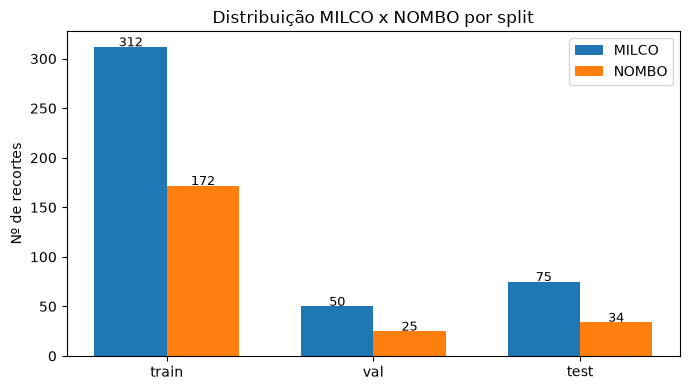

In [5]:

fig, ax = plt.subplots(figsize=(7, 4))
splits = list(contagens.keys())
x = np.arange(len(splits))
largura = 0.35

for i, classe in enumerate(CLASS_NAMES):
    valores = [contagens[s][classe] for s in splits]
    ax.bar(x + i * largura, valores, largura, label=classe)
    for xi, v in zip(x + i * largura, valores):
        ax.text(xi, v + 0.5, str(v), ha="center", fontsize=9)

ax.set_xticks(x + largura / 2)
ax.set_xticklabels(splits)
ax.set_ylabel("Nº de recortes")
ax.set_title("Distribuição MILCO x NOMBO por split")
ax.legend()
plt.tight_layout()
plt.show()


## 6. Datasets e DataLoaders (PyTorch `ImageFolder`)

In [6]:
# ImageFolder ordena as classes alfabeticamente: MILCO (0) antes de NOMBO (1),
# o que coincide com CLASS_NAMES - mas confira o print abaixo para garantir.
#
# Mudança da v2: o Dataset só redimensiona e converte para tensor em [0,1]. A augmentation roda em
# lote, na GPU (Seção 8), e cada backbone normaliza a entrada com a média/desvio do seu próprio pré-treino
# (dentro do modelo) - exatamente como no crop_harness.py do repositório.
transform_eval = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])
transform_train = transform_eval

ds_train_cls = datasets.ImageFolder(CROPS_DIR / "train", transform=transform_train)
ds_val_cls   = datasets.ImageFolder(CROPS_DIR / "val", transform=transform_eval)
ds_test_cls  = datasets.ImageFolder(CROPS_DIR / "test", transform=transform_eval)

print("Mapeamento de classes do ImageFolder:", ds_train_cls.class_to_idx)
assert list(ds_train_cls.class_to_idx.keys()) == CLASS_NAMES, (
    "A ordem das classes do ImageFolder não bate com CLASS_NAMES - ajuste CLASS_NAMES "
    "para a ordem mostrada acima antes de continuar."
)


def carregar_tensores(ds):
    # poucos recortes (centenas): cabem inteiros na memória, como no harness do repositório
    X = torch.stack([ds[i][0] for i in range(len(ds))])
    y = torch.tensor([ds.samples[i][1] for i in range(len(ds))], dtype=torch.long)
    return X, y


X_train, y_train = carregar_tensores(ds_train_cls)
X_val,   y_val   = carregar_tensores(ds_val_cls)
X_test,  y_test  = carregar_tensores(ds_test_cls)

print(f"Recortes - treino: {len(X_train)} | val: {len(X_val)} | teste: {len(X_test)}")

# pesos de classe SUAVIZADOS (dataset desbalanceado): 1 + SOFTEN * (peso_inverso - 1)
contagem_treino = np.bincount(y_train.numpy(), minlength=len(CLASS_NAMES))
peso_inverso = contagem_treino.sum() / (len(CLASS_NAMES) * np.maximum(contagem_treino, 1))
pesos_classe = torch.tensor(1 + SOFTEN * (peso_inverso - 1), dtype=torch.float32).to(device)
print("Contagem treino:", contagem_treino, "| pesos de classe:", pesos_classe.tolist())

Mapeamento de classes do ImageFolder: {'MILCO': 0, 'NOMBO': 1}
Recortes - treino: 484 | val: 75 | teste: 109
Contagem treino: [312 172] | pesos de classe: [0.8653846383094788, 1.2441860437393188]


## 7. Modelos: ConvNeXt-Pico (sozinho) e fusão ConvNeXt-Pico + MobileNetV2

Os dois usam a mesma classe. Com **um** backbone, a cabeça é `Dropout(0.3) → Linear`. Com **dois**, os vetores
de features são concatenados e passam por `Linear(256) → ReLU → Dropout(0.4) → Linear` (a mesma cabeça da fusão
anterior). Todos os pesos vêm do `timm` (`convnext_pico.d1_in1k`, `mobilenetv2_100.ra_in1k`) e **nenhuma camada
é congelada**.

In [7]:
def criar_backbone(nome):
    b = timm.create_model(nome, pretrained=True, num_classes=0)   # saída = vetor global (após pooling)
    dc = timm.data.resolve_data_config({}, model=b)
    b.register_buffer("mu", torch.tensor(dc["mean"]).view(1, 3, 1, 1), persistent=False)
    b.register_buffer("sd", torch.tensor(dc["std"]).view(1, 3, 1, 1), persistent=False)
    return b


class ClassificadorRecortes(nn.Module):
    """Entrada: imagens em [0,1]. Cada backbone normaliza com a média/desvio do seu pré-treino."""
    def __init__(self, nomes, num_classes=2):
        super().__init__()
        self.backbone = nn.ModuleList([criar_backbone(n) for n in nomes])

        # tamanho REAL das features (não confiar em num_features): mede com um tensor fake
        self.eval()
        with torch.no_grad():
            nf = sum(b(torch.zeros(1, 3, 64, 64)).shape[1] for b in self.backbone)
        self.train()

        if len(nomes) == 1:
            self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(nf, num_classes))
        else:
            self.head = nn.Sequential(nn.Linear(nf, 256), nn.ReLU(inplace=True),
                                      nn.Dropout(0.4), nn.Linear(256, num_classes))
        print(f"[ClassificadorRecortes] backbones={nomes} dim_features={nf}")

    def forward(self, x):
        feats = [b((x - b.mu) / b.sd) for b in self.backbone]
        return self.head(torch.cat(feats, dim=1))


def construir_modelo(modo):
    return ClassificadorRecortes(MODELOS_BACKBONES[modo], num_classes=len(CLASS_NAMES)).to(device)

## 8. Treinamento (fine-tuning completo — receita do repositório)

- Todos os parâmetros treináveis desde a 1ª época; AdamW com LR 10× maior na cabeça e `weight_decay=0,05`.
- LR com warmup linear (5%) e decaimento cosine, atualizado a cada passo.
- Augmentation em lote na GPU: flip horizontal + transformação afim (rot ±10°, zoom ±10%, deslocamento 5%)
  + brilho/contraste ±20%. **Sem flip vertical**: a sombra acústica do sonar tem direção fixa.
- O melhor checkpoint é escolhido pela **AUC MILCO×NOMBO na validação** (o teste não participa).

In [8]:
# ---------------------------------------------------------------- augmentation (porta de sonar_harness.augment)
def _afim(x, deg, scale, translate, gen):
    B, dev = x.shape[0], x.device
    r = lambda: torch.rand(B, generator=gen).to(dev)
    ang = (r() * 2 - 1) * math.radians(deg)
    sc = 1 + (r() * 2 - 1) * scale
    tx = (r() * 2 - 1) * translate * 2
    ty = (r() * 2 - 1) * translate * 2
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


def augmentar_batch(x, gen):
    B, dev = x.shape[0], x.device
    flip = (torch.rand(B, generator=gen) < 0.5).to(dev)
    x = torch.where(flip[:, None, None, None], x.flip(-1), x)          # só flip horizontal
    x = _afim(x, deg=10, scale=0.10, translate=0.05, gen=gen)
    b = 1 + (torch.rand(B, 1, 1, 1, generator=gen).to(dev) * 2 - 1) * 0.2
    c = 1 + (torch.rand(B, 1, 1, 1, generator=gen).to(dev) * 2 - 1) * 0.2
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = ((x - m) * c + m) * b
    return x.clamp(0, 1)


def fator_lr(passo, total):
    warm = max(1, int(total * WARMUP_FRAC))
    if passo < warm:
        return (passo + 1) / warm
    prog = (passo - warm) / max(1, total - warm)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))


# ---------------------------------------------------------------- predição / métricas
@torch.no_grad()
def prever(model, X, bs=64, tta=False):
    """Probabilidades [N, 2]. tta=True faz a média com a versão espelhada (flip horizontal)."""
    model.eval()
    saidas = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].to(device)
        p = torch.softmax(model(x), dim=1)
        if tta:
            p = 0.5 * (p + torch.softmax(model(x.flip(-1)), dim=1))
        saidas.append(p.cpu())
    return torch.cat(saidas).numpy()


def auc_milco_nombo(y, P):
    return float(roc_auc_score(np.asarray(y) == 0, P[:, 0]))


# ---------------------------------------------------------------- treino
def treinar(modo, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    model = construir_modelo(modo)
    ckpt = CHECKPOINT_DIR / f"clf_{modo}_s{seed}.pt"

    grupos = [
        {"params": list(model.backbone.parameters()), "lr": LR,                 "initial_lr": LR},
        {"params": list(model.head.parameters()),     "lr": LR * HEAD_LR_MULT,  "initial_lr": LR * HEAD_LR_MULT},
    ]
    opt = torch.optim.AdamW(grupos, lr=LR, weight_decay=WEIGHT_DECAY)

    bs = BATCH_SIZE[modo]
    passos_por_epoca = math.ceil(len(X_train) / bs)
    total = passos_por_epoca * EPOCHS
    gen = torch.Generator().manual_seed(seed)

    hist = {"train_loss": [], "val_auc": [], "val_acc": []}
    melhor, sem_melhora, passo = -1.0, 0, 0

    for epoca in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(X_train), generator=gen)
        soma, n = 0.0, 0
        for k in range(passos_por_epoca):
            idx = perm[k * bs:(k + 1) * bs]
            if len(idx) < 2:          # BatchNorm do MobileNetV2 não aceita lote de 1 amostra
                continue
            xb = augmentar_batch(X_train[idx].to(device), gen)
            yb = y_train[idx].to(device)

            f = fator_lr(passo, total)
            for g in opt.param_groups:
                g["lr"] = g["initial_lr"] * f

            loss = F.cross_entropy(model(xb), yb, weight=pesos_classe)
            opt.zero_grad()
            loss.backward()
            opt.step()
            passo += 1
            soma += loss.item() * len(idx); n += len(idx)

        Pv = prever(model, X_val)
        auc = auc_milco_nombo(y_val.numpy(), Pv)
        acc = float((Pv.argmax(1) == y_val.numpy()).mean())
        hist["train_loss"].append(soma / max(1, n)); hist["val_auc"].append(auc); hist["val_acc"].append(acc)
        print(f"[{modo}] época {epoca}/{EPOCHS} - loss treino: {soma / max(1, n):.4f} - "
              f"AUC val: {auc:.4f} - acc val: {acc:.4f}")

        if auc > melhor + 1e-4:
            melhor, sem_melhora = auc, 0
            torch.save(model.state_dict(), ckpt)
        else:
            sem_melhora += 1
            if sem_melhora >= PATIENCE:
                print("EarlyStopping acionado.")
                break

    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()
    print(f"[{modo}] melhor AUC de validação: {melhor:.4f} (checkpoint: {ckpt.name})")
    return model, hist


modelos, historicos = {}, {}
for modo in MODOS_TREINO:
    print(f"\n>>> Treinando modo '{modo}': {MODELOS_BACKBONES[modo]}")
    modelos[modo], historicos[modo] = treinar(modo)

# o resto do notebook (grade 4x4 e pipeline YOLO) usa `fusion_model`
fusion_model = modelos[MODO_FINAL]
fusion_model.eval()
print(f"\nModelo usado nas Seções 10 e 11: '{MODO_FINAL}'")


>>> Treinando modo 'convnext': ['convnext_pico']


C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuário\.cache\huggingface\hub\models--timm--convnext_pico.d1_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[ClassificadorRecortes] backbones=['convnext_pico'] dim_features=512
[convnext] época 1/30 - loss treino: 0.6655 - AUC val: 0.7144 - acc val: 0.7067
[convnext] época 2/30 - loss treino: 0.6266 - AUC val: 0.7824 - acc val: 0.8400
[convnext] época 3/30 - loss treino: 0.4711 - AUC val: 0.7232 - acc val: 0.4933
[convnext] época 4/30 - loss treino: 0.5176 - AUC val: 0.7904 - acc val: 0.7200
[convnext] época 5/30 - loss treino: 0.5172 - AUC val: 0.8432 - acc val: 0.7467
[convnext] época 6/30 - loss treino: 0.3760 - AUC val: 0.8632 - acc val: 0.8533
[convnext] época 7/30 - loss treino: 0.3621 - AUC val: 0.7872 - acc val: 0.7733
[convnext] época 8/30 - loss treino: 0.4087 - AUC val: 0.8544 - acc val: 0.8267
[convnext] época 9/30 - loss treino: 0.2659 - AUC val: 0.9112 - acc val: 0.8000
[convnext] época 10/30 - loss treino: 0.2716 - AUC val: 0.9064 - acc val: 0.8133
[convnext] época 11/30 - loss treino: 0.2164 - AUC val: 0.9512 - acc val: 0.9067
[convnext] época 12/30 - loss treino: 0.2493 - AU

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Usuário\.cache\huggingface\hub\models--timm--mobilenetv2_100.ra_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


[ClassificadorRecortes] backbones=['convnext_pico', 'mobilenetv2_100'] dim_features=1792
[fusao] época 1/30 - loss treino: 0.6527 - AUC val: 0.8552 - acc val: 0.7733
[fusao] época 2/30 - loss treino: 0.5900 - AUC val: 0.8848 - acc val: 0.8667
[fusao] época 3/30 - loss treino: 0.5374 - AUC val: 0.7416 - acc val: 0.6000
[fusao] época 4/30 - loss treino: 0.4555 - AUC val: 0.8208 - acc val: 0.7600
[fusao] época 5/30 - loss treino: 0.4522 - AUC val: 0.8088 - acc val: 0.7467
[fusao] época 6/30 - loss treino: 0.3949 - AUC val: 0.8416 - acc val: 0.7600
[fusao] época 7/30 - loss treino: 0.3140 - AUC val: 0.8648 - acc val: 0.7733
[fusao] época 8/30 - loss treino: 0.2931 - AUC val: 0.8712 - acc val: 0.7600
[fusao] época 9/30 - loss treino: 0.2564 - AUC val: 0.8536 - acc val: 0.7600
[fusao] época 10/30 - loss treino: 0.2059 - AUC val: 0.8600 - acc val: 0.8133
EarlyStopping acionado.
[fusao] melhor AUC de validação: 0.8848 (checkpoint: clf_fusao_s42.pt)

Modelo usado nas Seções 10 e 11: 'convnext'


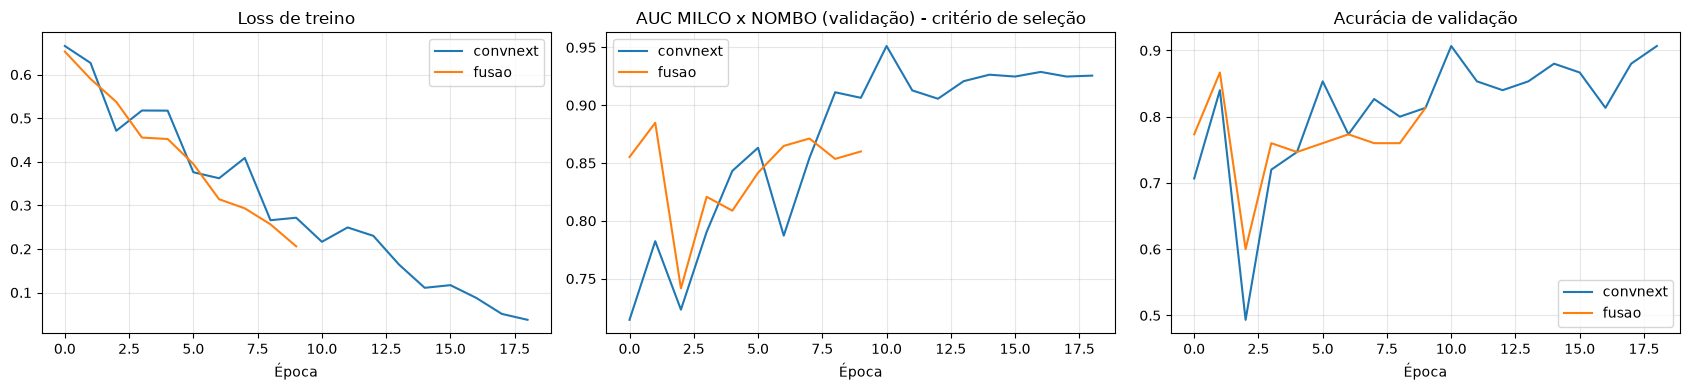

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
for modo, h in historicos.items():
    axs[0].plot(h["train_loss"], label=modo)
    axs[1].plot(h["val_auc"], label=modo)
    axs[2].plot(h["val_acc"], label=modo)

axs[0].set_title("Loss de treino"); axs[1].set_title("AUC MILCO x NOMBO (validação) - critério de seleção")
axs[2].set_title("Acurácia de validação")
for ax in axs:
    ax.set_xlabel("Época"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Avaliação no conjunto de teste


===== convnext: ['convnext_pico'] =====
[convnext] sem TTA         acc 0.8624 | prec 0.8689 | rec 0.8624 | F1 0.8538 | AUC 0.9333
[convnext] com TTA (flip)  acc 0.8532 | prec 0.8558 | rec 0.8532 | F1 0.8451 | AUC 0.9294
              precision    recall  f1-score   support

       MILCO       0.85      0.97      0.91        75
       NOMBO       0.91      0.62      0.74        34

    accuracy                           0.86       109
   macro avg       0.88      0.80      0.82       109
weighted avg       0.87      0.86      0.85       109


===== fusao: ['convnext_pico', 'mobilenetv2_100'] =====
[fusao] sem TTA         acc 0.7890 | prec 0.7847 | rec 0.7890 | F1 0.7862 | AUC 0.7533
[fusao] com TTA (flip)  acc 0.8073 | prec 0.8017 | rec 0.8073 | F1 0.8006 | AUC 0.7384
              precision    recall  f1-score   support

       MILCO       0.83      0.87      0.85        75
       NOMBO       0.68      0.62      0.65        34

    accuracy                           0.79       109
   

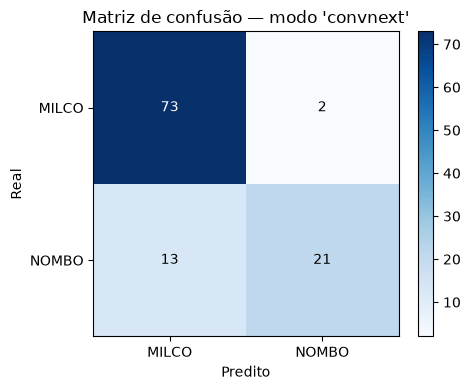

In [10]:
def avaliar_modelo(model, nome):
    y_true = y_test.numpy()
    resumo = {}
    for rotulo, tta in (("sem TTA", False), ("com TTA (flip)", True)):
        P = prever(model, X_test, tta=tta)
        y_pred = P.argmax(1)
        acc = accuracy_score(y_true, y_pred)
        prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
        auc = auc_milco_nombo(y_true, P)
        resumo[rotulo] = dict(acc=acc, prec=prec, rec=rec, f1=f1, auc=auc, y_pred=y_pred)
        print(f"[{nome}] {rotulo:15s} acc {acc:.4f} | prec {prec:.4f} | rec {rec:.4f} | F1 {f1:.4f} | AUC {auc:.4f}")
    return resumo


resultados_teste = {}
for modo, m in modelos.items():
    print(f"\n===== {modo}: {MODELOS_BACKBONES[modo]} =====")
    resultados_teste[modo] = avaliar_modelo(m, modo)
    print(classification_report(y_test.numpy(), resultados_teste[modo]["sem TTA"]["y_pred"],
                                target_names=CLASS_NAMES, zero_division=0))

print("\nResumo no teste (referência do repositório: convnext_pico sozinho ~0,90; fusão com MobileNetV2 ~0,76):")
for modo, r in resultados_teste.items():
    print(f"  {modo:9s} acc {r['sem TTA']['acc']:.4f} | acc TTA {r['com TTA (flip)']['acc']:.4f} | "
          f"AUC {r['sem TTA']['auc']:.4f}")

# matriz de confusão do modelo final
y_pred = resultados_teste[MODO_FINAL]["sem TTA"]["y_pred"]
cm = confusion_matrix(y_test.numpy(), y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASS_NAMES))); ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predito"); ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusão — modo '{MODO_FINAL}'")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()

## 10. Grade de recortes — real x predito (4x4)

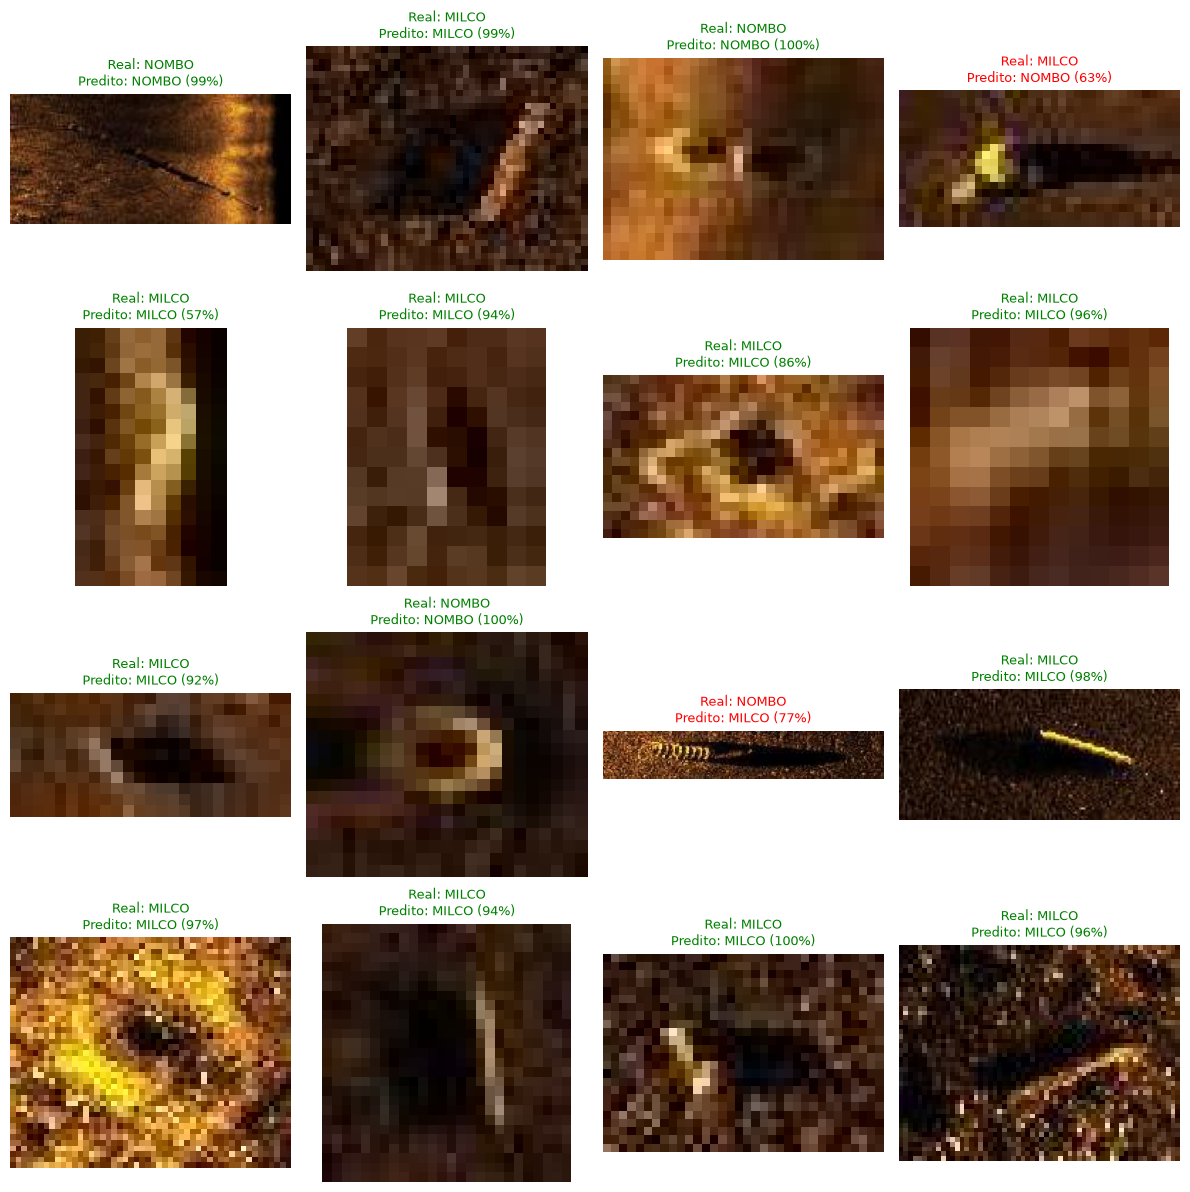

In [11]:

transform_classificacao = transform_eval

@torch.no_grad()
def classificar_recorte(caminho_recorte):
    img = Image.open(caminho_recorte).convert("RGB")
    tensor = transform_classificacao(img).unsqueeze(0).to(device)
    probs = torch.softmax(fusion_model(tensor), dim=1)[0].cpu().numpy()
    idx = int(np.argmax(probs))
    return CLASS_NAMES[idx], float(probs[idx])


def plotar_grade_recortes(dataset, n_linhas=4, n_colunas=4, seed=0):
    rnd = random.Random(seed)
    indices = rnd.sample(range(len(dataset.samples)), min(n_linhas * n_colunas, len(dataset.samples)))

    fig, axs = plt.subplots(n_linhas, n_colunas, figsize=(3 * n_colunas, 3 * n_linhas))
    axs = axs.flatten()

    for ax, idx in zip(axs, indices):
        caminho, classe_real_idx = dataset.samples[idx]
        classe_real = CLASS_NAMES[classe_real_idx]
        classe_predita, confianca = classificar_recorte(caminho)

        img = Image.open(caminho).convert("RGB")
        ax.imshow(img)
        cor = "green" if classe_predita == classe_real else "red"
        ax.set_title(f"Real: {classe_real}\nPredito: {classe_predita} ({confianca*100:.0f}%)",
                     fontsize=9, color=cor)
        ax.axis("off")

    for ax in axs[len(indices):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


plotar_grade_recortes(ds_test_cls, n_linhas=4, n_colunas=4)



## 11. Pipeline fim-a-fim: YOLO (detecção) + fusão (classificação), com caixa desenhada

Aponte `CAMINHO_PESOS_YOLO` para o `best.pt` do modelo que você escolher (Modelo A ou B, o que
teve melhor `AR_small`/mAP na comparação do outro notebook).


In [12]:

from ultralytics import YOLO

CAMINHO_PESOS_YOLO = Path(r"D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelA_yolo_p2\weights\best.pt") # <-- ajuste
detector = YOLO(CAMINHO_PESOS_YOLO)


@torch.no_grad()
def detectar_e_classificar(imagem_path, score_thresh=0.5, margin=CROP_MARGIN):
    img = Image.open(imagem_path).convert("RGB")
    w, h = img.size

    saida_yolo = detector.predict(source=str(imagem_path), conf=score_thresh, verbose=False)[0]

    resultados = []
    for box in saida_yolo.boxes:
        xmin, ymin, xmax, ymax = box.xyxy[0].tolist()
        score = float(box.conf[0])
        bw, bh = xmax - xmin, ymax - ymin

        xmin_m = max(0, xmin - bw * margin)
        ymin_m = max(0, ymin - bh * margin)
        xmax_m = min(w, xmax + bw * margin)
        ymax_m = min(h, ymax + bh * margin)

        crop = img.crop((xmin_m, ymin_m, xmax_m, ymax_m))
        crop_tensor = transform_classificacao(crop).unsqueeze(0).to(device)
        probs = torch.softmax(fusion_model(crop_tensor), dim=1)[0].cpu().numpy()
        classe_idx = int(np.argmax(probs))

        resultados.append({
            "box": (xmin, ymin, xmax, ymax),
            "score_deteccao": score,
            "classe": CLASS_NAMES[classe_idx],
            "confianca_classificacao": float(probs[classe_idx]),
        })

    return img, resultados


def plotar_resultado(img, resultados, titulo=None):
    cores = {"MILCO": "cyan", "NOMBO": "yellow"}
    fig, ax = plt.subplots(1, figsize=(8, 8))
    ax.imshow(img)
    for r in resultados:
        xmin, ymin, xmax, ymax = r["box"]
        cor = cores.get(r["classe"], "red")
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                  linewidth=2, edgecolor=cor, facecolor="none")
        ax.add_patch(rect)
        rotulo = f"{r['classe']} ({r['confianca_classificacao']*100:.1f}%)"
        ax.text(xmin, max(ymin - 5, 0), rotulo, color=cor, fontsize=10, weight="bold",
                bbox=dict(facecolor="black", alpha=0.4, pad=1))
    ax.axis("off")
    if titulo:
        ax.set_title(titulo)
    plt.show()


0001_2015.jpg -> [{'box': (79.6243667602539, 212.3608856201172, 131.77432250976562, 250.9516143798828), 'score_deteccao': 0.9273697137832642, 'classe': 'MILCO', 'confianca_classificacao': 0.9888898134231567}, {'box': (911.7950439453125, 966.5802001953125, 965.6376342773438, 998.6981811523438), 'score_deteccao': 0.7582631707191467, 'classe': 'NOMBO', 'confianca_classificacao': 0.9795140027999878}]
0002_2015.jpg -> [{'box': (174.6575469970703, 296.97747802734375, 184.61927795410156, 312.85565185546875), 'score_deteccao': 0.7918393015861511, 'classe': 'MILCO', 'confianca_classificacao': 0.7073265314102173}, {'box': (324.91204833984375, 401.6396179199219, 345.9027099609375, 412.13671875), 'score_deteccao': 0.7498466372489929, 'classe': 'MILCO', 'confianca_classificacao': 0.9755598306655884}, {'box': (369.9436950683594, 58.97100067138672, 392.19818115234375, 73.10289764404297), 'score_deteccao': 0.710652232170105, 'classe': 'MILCO', 'confianca_classificacao': 0.6624141335487366}, {'box': (3

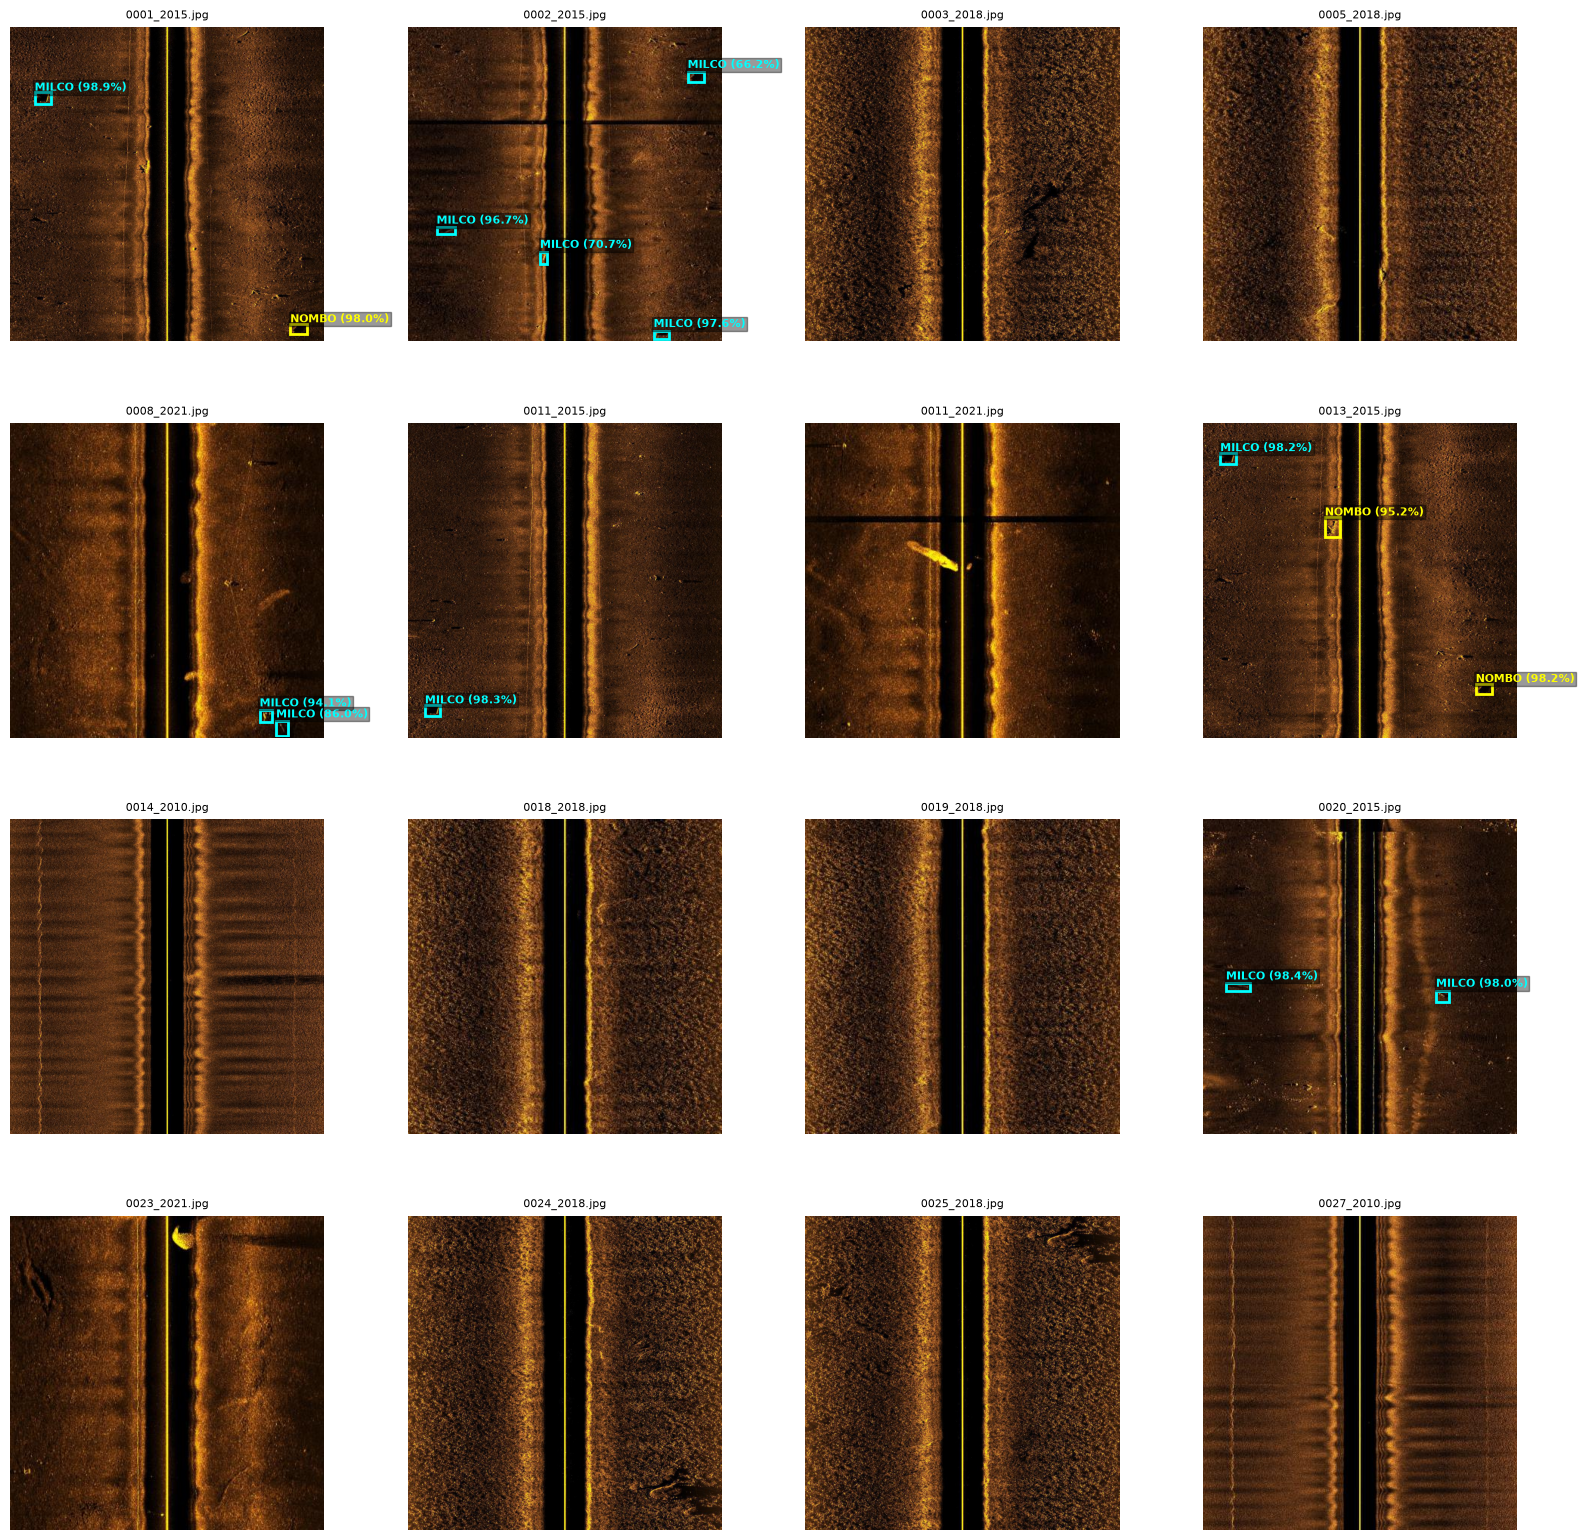

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Ajuste leve na sua função plotar_resultado para aceitar 'ax'
def plotar_resultado(img, resultados, titulo=None, ax=None):
    cores = {"MILCO": "cyan", "NOMBO": "yellow"}
    
    # Se nenhum eixo for passado, cria uma figura individual (mantém o comportamento original)
    if ax is None:
        fig, ax = plt.subplots(1, figsize=(8, 8))
        mostrar_no_final = True
    else:
        mostrar_no_final = False

    ax.imshow(img)
    
    for r in resultados:
        xmin, ymin, xmax, ymax = r["box"]
        cor = cores.get(r["classe"], "red")
        
        rect = patches.Rectangle(
            (xmin, ymin), xmax - xmin, ymax - ymin,
            linewidth=2, edgecolor=cor, facecolor="none"
        )
        ax.add_patch(rect)
        
        rotulo = f"{r['classe']} ({r['confianca_classificacao']*100:.1f}%)"
        ax.text(
            xmin, max(ymin - 5, 0), rotulo, color=cor, fontsize=8, weight="bold",
            bbox=dict(facecolor="black", alpha=0.4, pad=1)
        )
        
    ax.axis("off")
    if titulo:
        ax.set_title(titulo, fontsize=8)
        
    if mostrar_no_final:
        plt.show()


# 2. Execução da grade 4x4 (16 imagens)
imagens_teste_completas = sorted((YOLO_DIR / "images" / "test").glob("*.jpg"))[:16]

# Cria o painel 4x4 de uma só vez
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
axes_flat = axes.flatten()

for i, img_path in enumerate(imagens_teste_completas):
    img, resultados = detectar_e_classificar(img_path, score_thresh=0.5)
    
    # Passa o eixo específico da grade (axes_flat[i]) para a função desenhar nele
    plotar_resultado(img, resultados, titulo=img_path.name, ax=axes_flat[i])
    print(img_path.name, "->", resultados)

# Desativa eixos vazios caso haja menos de 16 imagens na pasta
for j in range(len(imagens_teste_completas), 16):
    axes_flat[j].axis("off")

plt.tight_layout()
plt.show()